# Trustworthy AI for Open RAN — Overview

This notebook is the **entry point**. It shows the project layout, the six analysable datasets, and runs one full four-pillar analysis end-to-end using the exact same `trustoran` package that the CLI (`py/main_cli.py`) and the Qt studio (`QtUI/main.py`) drive.

| Layer | Location | Role |
|---|---|---|
| Engineering package | `py/trustoran/` | data · models · four trust pillars · viz · pipeline |
| CLI | `py/main_cli.py`, `py/run_all.py` | headless runs, exports to `results/` |
| Notebooks | `ipynb/` | the visual walkthroughs (this folder) |
| Qt studio | `QtUI/` | interactive panels **+** a simulated O-RAN SMO / Near-RT RIC console |

> Every figure below is produced by a `trustoran.viz.plotting.fig_*` factory — the notebook, the CLI export and the Qt canvas all call the *same* function.

In [1]:
# --- bootstrap: make the `trustoran` engineering package importable ---------
import sys, pathlib
REPO = pathlib.Path.cwd().resolve()
while not (REPO / "py" / "trustoran").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "py"))

%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from trustoran import config as C
from trustoran.data import build_dataset, train_test_split_dataset
from trustoran.data.loaders import available_datasets
from trustoran.models import make_model
from trustoran.pipeline.engine import TrustPipeline, PILLARS, DATASET_PROFILES
from trustoran.viz import plotting as VZ
from trustoran.trust import explainability as EX, robustness as RB, fairness as FA, privacy as PR

print("repo root :", REPO)
print("datasets  :", available_datasets())
print("pillars   :", PILLARS)

repo root : E:\可信AI
datasets  : ['cci_a1sd', 'cci_a1sd_binary', 'ddos_pcap', 'vran_energy', 'vran_application', 'vran_computing']
pillars   : ('explainability', 'robustness', 'fairness', 'privacy')


## 1 · The dataset catalogue

Three Open RAN sources are wrapped behind one `TrustDataset` interface (`X`, `y`, `groups`, `task`, `class_names`):

In [2]:
for key in available_datasets():
    prof = DATASET_PROFILES.get(key, {})
    print(f"- {key:18s} task={prof.get('regression') and 'regression' or 'classification'}"
          f"  group={prof.get('fairness_group')}  | {prof.get('note','')}")

- cci_a1sd           task=classification  group=policy_name  | A1 traffic: Normal/DoS/Covert detection
- cci_a1sd_binary    task=classification  group=policy_name  | A1 traffic: Normal vs DoS
- ddos_pcap          task=classification  group=agent  | Near-RT RIC edge DDoS detection across 5 agents
- vran_energy        task=regression  group=cpu_platform  | BBU power regression
- vran_application   task=regression  group=gpu_platform  | Edge-AI end-to-end delay regression
- vran_computing     task=classification  group=n_vbs  | vRAN deployment failure (explode) classification


In [3]:
# Peek at one dataset's schema (sampled for speed).
ds = build_dataset("cci_a1sd", max_rows=4000, seed=42)
print(ds.describe())
ds.X.head()

{'name': 'cci_a1sd', 'task': 'classification', 'n_samples': 12000, 'n_features': 10, 'feature_names': ['real_interval', 'inter_arrival_mean', 'inter_arrival_std', 'inter_arrival_cv', 'response_time_mean', 'response_time_std', 'request_rate', 'payload_size_mean', 'payload_size_std', 'body_size'], 'class_names': ['Normal', 'Dos', 'Covert'], 'class_counts': {'Normal': 4000, 'Dos': 4000, 'Covert': 4000}, 'group_attrs': ['policy_type_id', 'load_label', 'operation', 'policy_name'], 'meta': {'source': 'CCI-A1SD', 'dos_variant': 'dos2', 'classes': ['normal', 'dos', 'covert'], 'per_class_cap': 20000, 'policy_names': {20008: 'Traffic Steering', 20009: 'QoS Management', 20010: 'Resource Allocation', 20011: 'Slice SLA', 20012: 'Energy Saving', 20013: 'Load Balancing', 20014: 'Cell Barring', 20015: 'Handover Steering'}}}


,real_interval,inter_arrival_mean,inter_arrival_std,inter_arrival_cv,response_time_mean,response_time_std,request_rate,payload_size_mean,payload_size_std,body_size
0,57.297461,57.297461,0.000000,0.000000,0.018452,0.000000,0.000000,96.0,0.0,96
1,155.152341,155.152341,0.000000,0.000000,0.019403,0.000000,0.000000,96.0,0.0,96
2,187.596854,187.596854,0.000000,0.000000,0.021669,0.000000,0.000000,135.0,0.0,135
3,249.184776,249.184776,0.000000,0.000000,0.023950,0.000000,0.000000,189.0,0.0,189
4,266.081032,161.689246,104.391786,0.645632,0.016457,0.001996,0.007517,96.0,0.0,96


## 2 · One-call four-pillar analysis

`TrustPipeline(...).run()` is the single object the CLI, the notebooks and the Qt UI all drive. It loads → splits → trains → runs the requested pillars → returns an `AnalysisReport` holding every metric, table and `Figure`.

In [4]:
def progress(stage, pct, msg):
    print(f"[{pct*100:5.1f}%] {stage:14s} {msg}")

pipe = TrustPipeline(dataset_key="cci_a1sd_binary", model_name="random_forest",
                     pillars=PILLARS, quick=True, seed=42)
report = pipe.run(progress_cb=progress)
report.headline()

[  2.0%] load           loading cci_a1sd_binary
[  8.0%] split          splitting & scaling
[ 16.0%] train          training random_forest


[ 26.0%] overview       building overview figures


[ 30.0%] explainability running explainability
[ 31.7%] explainability permutation importance


[ 36.8%] explainability SHAP attributions


[ 40.2%] explainability local explanation
[ 43.6%] explainability partial dependence


...

[ 56.4%] robustness     robustness curves


[ 61.5%] robustness     adversarial training


[ 64.0%] fairness       running fairness
[ 72.5%] fairness       auditing groups by policy_name
[ 81.0%] privacy        running privacy
[ 85.2%] privacy        differential privacy curve


[ 96.3%] privacy        membership inference
[100.0%] done           finished in 67.5s


'[cci_a1sd_binary] random_forest — accuracy=1.000'

### 2.1 · Overview figures (dataset + base model)

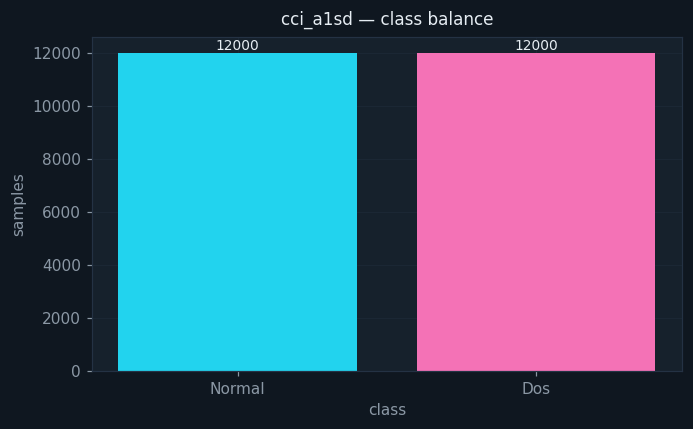

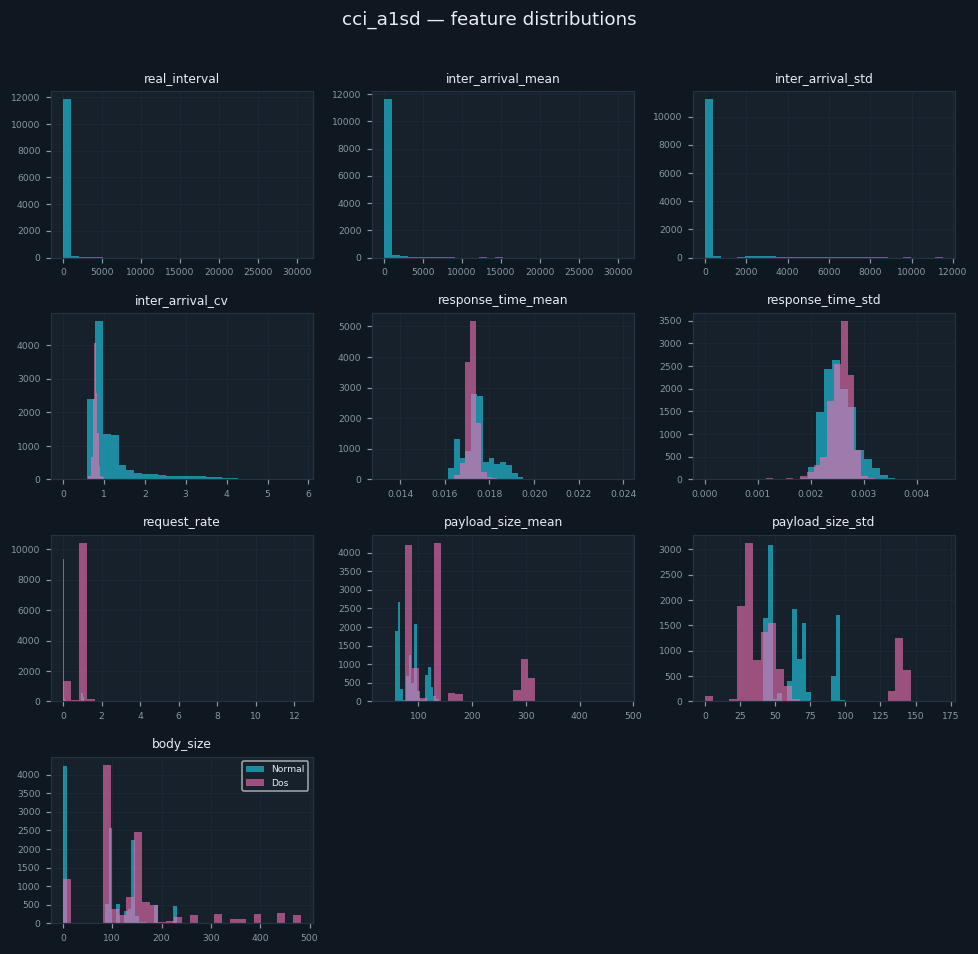

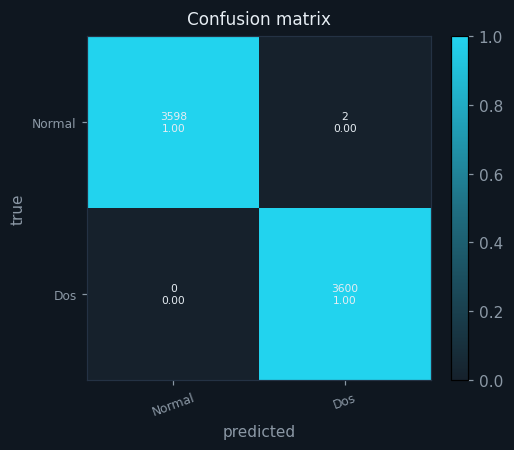

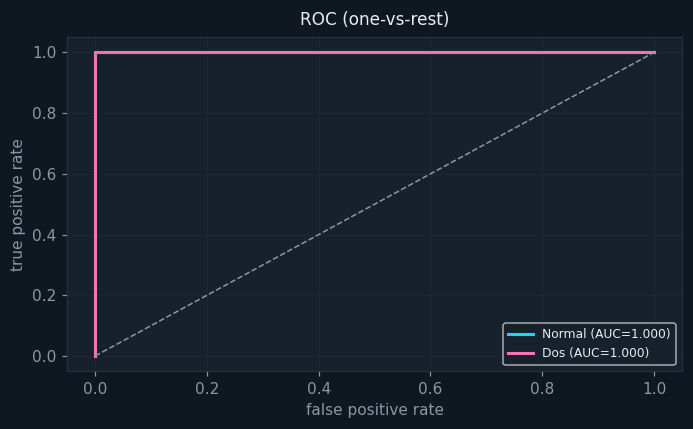

In [5]:
for name, fig in report.base_figures.items():
    display(fig)

### 2.2 · Every pillar's figures


====  EXPLAINABILITY  ====
summary: {'top_features': ['inter_arrival_std', 'response_time_mean', 'payload_size_std', 'payload_size_mean', 'real_interval'], 'target': 'P(class 1)', 'shap_top': ['inter_arrival_std', 'request_rate', 'inter_arrival_mean', 'payload_size_std', 'payload_size_mean'], 'method': 'permutation + KernelSHAP + LIME-style local + PDP/ICE'}


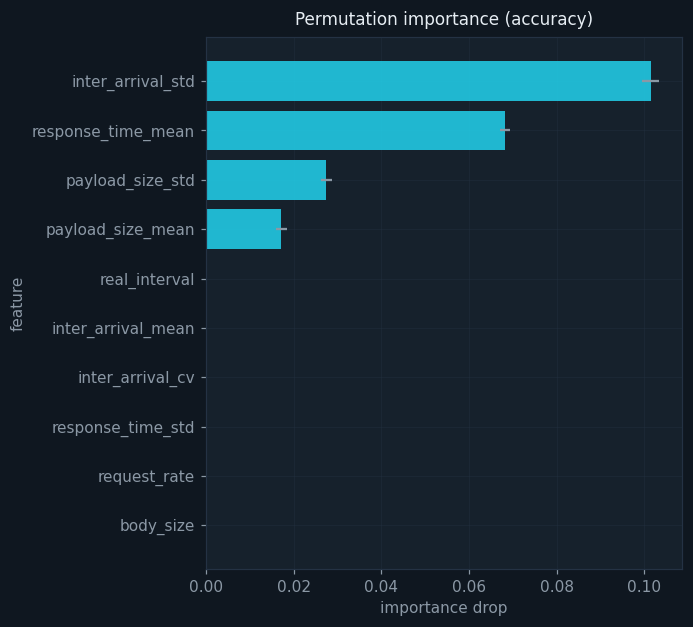

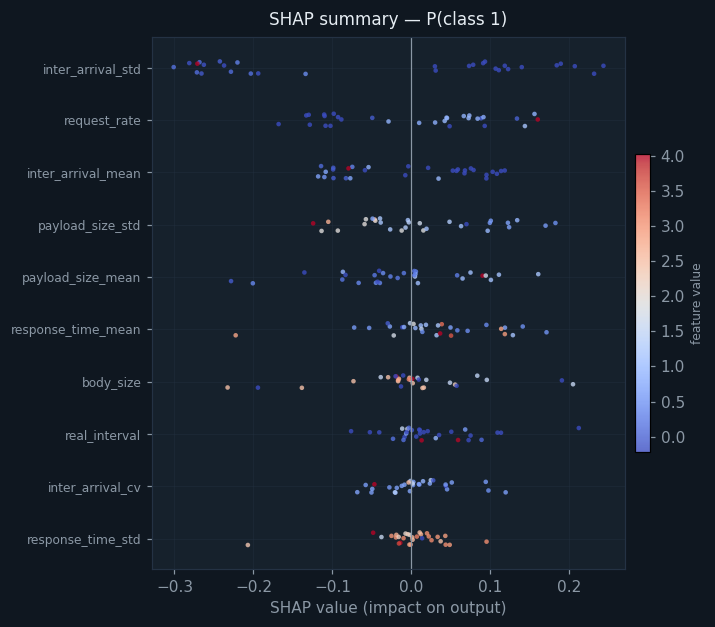

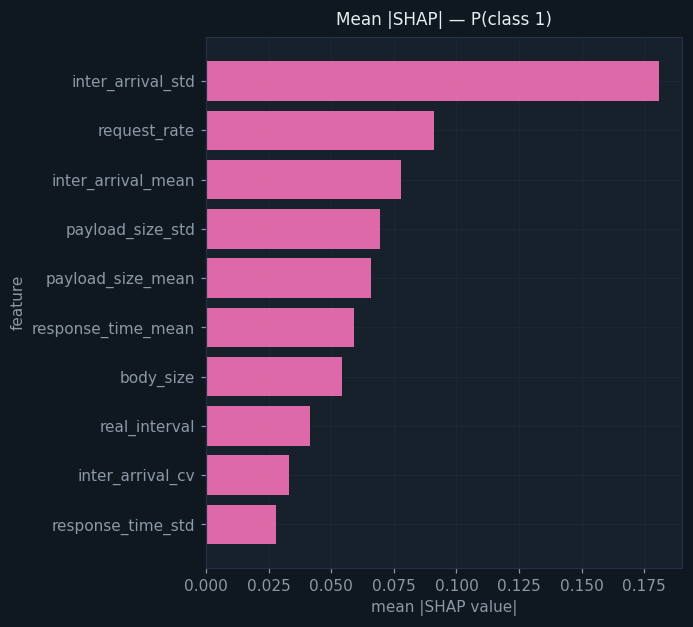

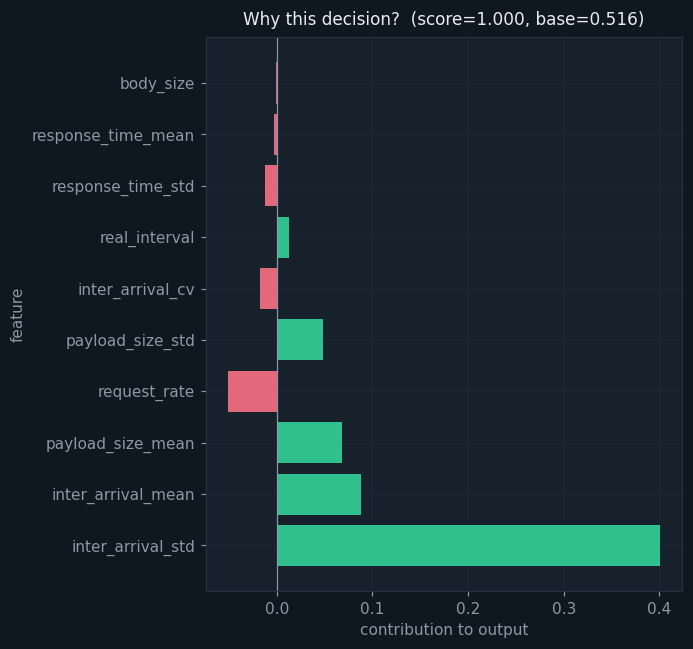

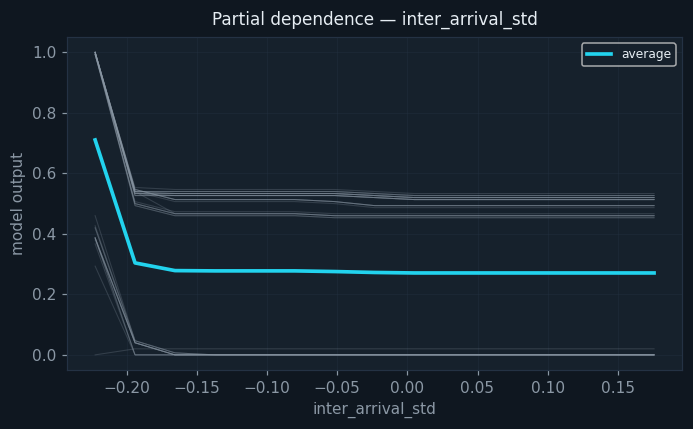

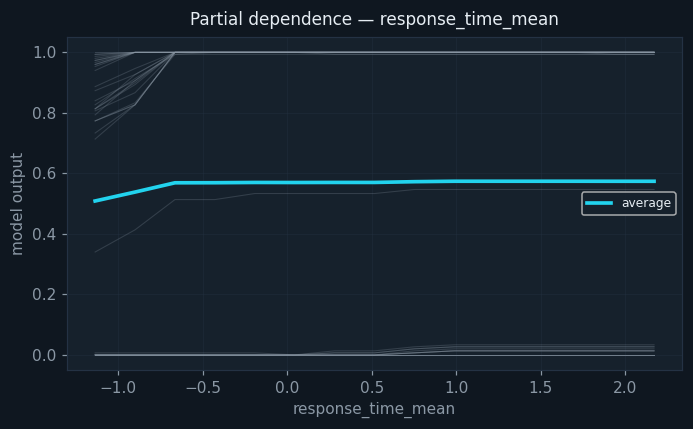


====  ROBUSTNESS  ====
summary: {'clean_accuracy': 1.0, 'fgsm_robust_acc': 0.9533333333333334, 'pgd_robust_acc': 0.74, 'deepfool_robust_acc': 1.0, 'pgd_attack_success_rate': 0.26, 'adv_trained_robust_acc@eps0.6': 0.9866666666666667}


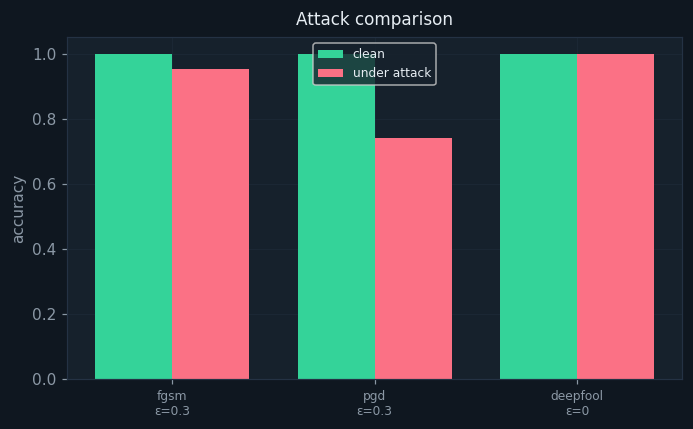

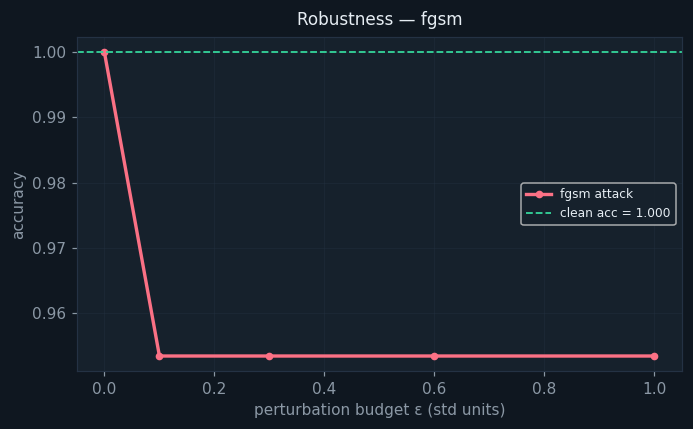

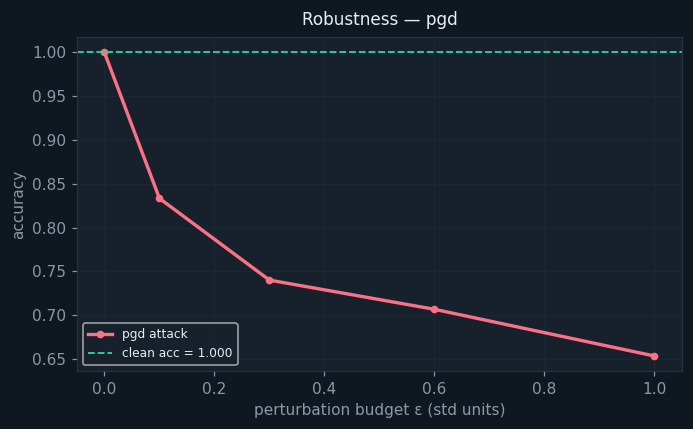

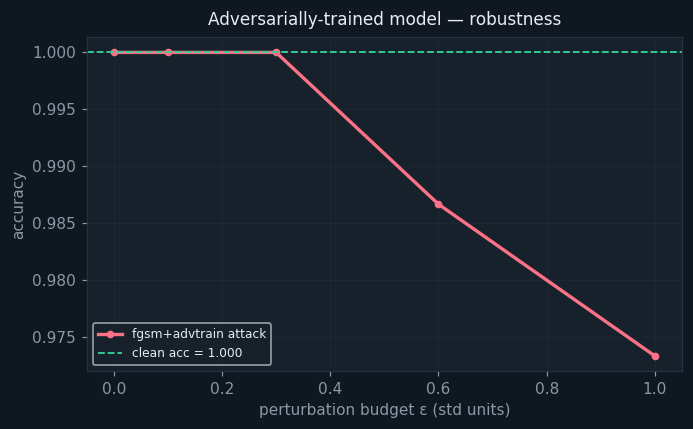


====  FAIRNESS  ====
summary: {'group_attr': 'policy_name', 'n_groups': 8, 'demographic_parity_difference': 0.212, 'demographic_parity_ratio': 0.6897, 'disparate_impact': 0.6897, 'equal_opportunity_difference': 0.0}


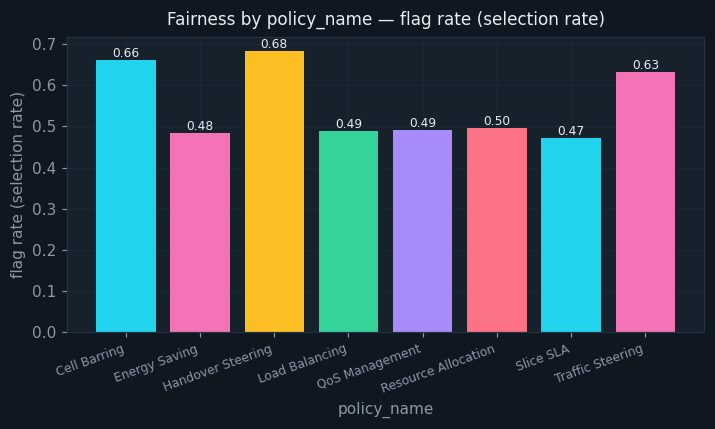

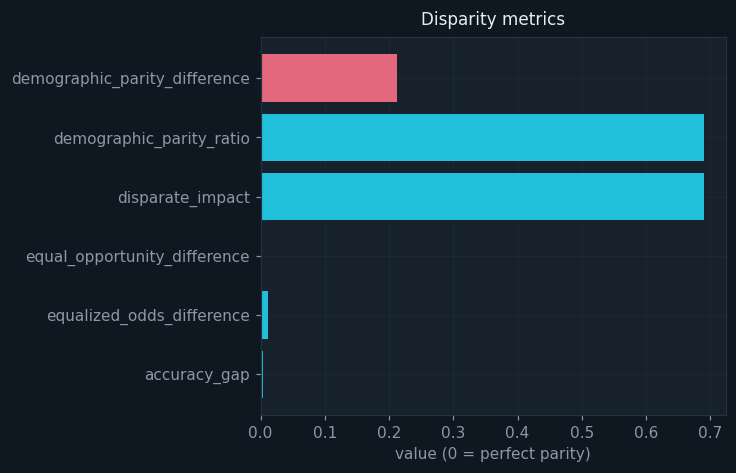


====  PRIVACY  ====
summary: {'dp_mechanism': 'gaussian (DP-SGD)', 'utility_open': 0.9986666666666667, 'utility_eps1': 0.9986666666666667, 'utility_eps0.1': 0.9746666666666667, 'membership_inference_auc': 0.5227305555555555}


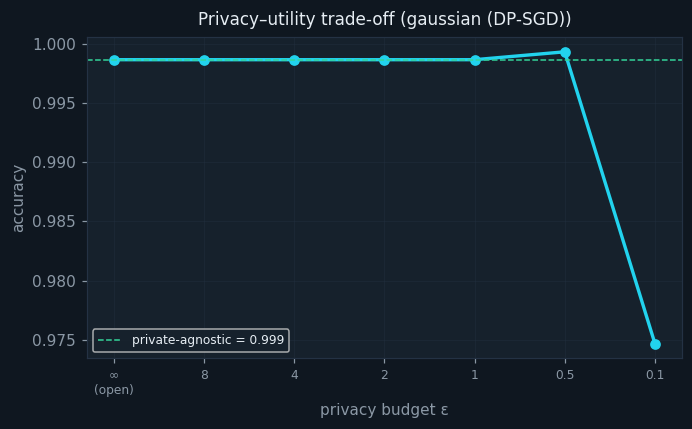

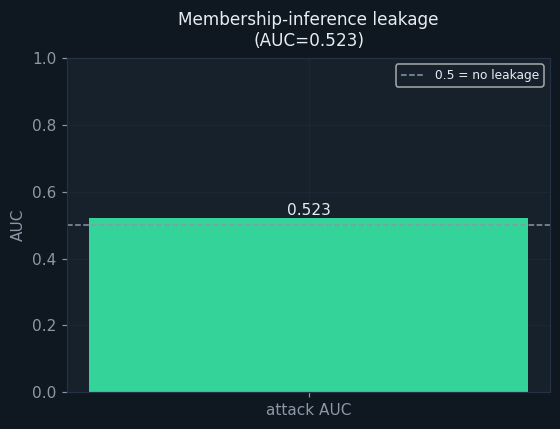

In [6]:
for pillar, res in report.pillars.items():
    print("\n==== ", pillar.upper(), " ====")
    print("summary:", {k: res.summary[k] for k in list(res.summary)[:6]})
    for name, fig in res.figures.items():
        display(fig)

## 3 · Exporting results

The report can write `report.json` + CSV tables + PNG figures into `results/<dataset>/` — this is exactly what the CLI and `run_all.py` do.

`run_all.py` also writes `results/index.json`, a per-model summary of all six profiles. Two archived runs are in the repo: `results/` (random_forest, attribution via the sampled path) and `results/exact_xgboost/` (xgboost, attribution via native exact contributions), so the two routing branches can be compared without re-running anything.


In [7]:
written = report.export(C.RESULTS_DIR)
{cat: len(paths) for cat, paths in written.items()}

{'report': 1, 'tables': 11, 'figures': 18}

## Next

* `01_cci_a1sd_full_trust.ipynb` — A1 traffic, all four pillars, function-by-function.
* `02_ddos_pcap_federated.ipynb` — edge DDoS PCAPs + FedAvg across 5 agents.
* `03_vran_energy_fairness_dp.ipynb` — regression trust (BBU power).
* `04_api_cookbook.ipynb` — the low-level unified API and the full `fig_*` catalogue.
* `05_ours_vs_opensource.ipynb` — our engines measured against `shap` / `captum` / `opacus`-style reference implementations on the same model and data.
* `06_shap_exact_vs_sampled.ipynb` — exact (TreeSHAP) vs sampled attribution: routing, the efficiency identity, agreement with `shap.TreeExplainer`, and per-sample cost.
